# Lab 03 - BPE and WordPiece on IndicCorpV2

This notebook downloads one IndicCorpV2 language, creates train/development/test splits, trains BPE and WordPiece tokenizers, and compares tokenization when training-data size and vocabulary size change.

## Step 1 - Imports and Settings

Change `LANGUAGE_CODE` if your assigned language is different. For the full assignment keep the four training sizes and three vocabulary sizes as given.

In [1]:
import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.normalizers import NFKC, Sequence
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.processors import TemplateProcessing

random.seed(42)
np.random.seed(42)

LANGUAGE_CODE = "hin_Deva"   # Change this if needed, for example: tam_Taml, ben_Beng, tel_Telu
LANGUAGE_NAME = "Hindi"

DEV_SIZE = 1000
TEST_SIZE = 1000
TRAINING_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]

MIN_SENT_LEN = 5
MAX_SENT_LEN = 500
MAX_DOCS_TO_SCAN = 5_000_000

DATA_DIR = Path("lab03_data")
DATA_DIR.mkdir(exist_ok=True)

ALL_SENTENCES_CSV = DATA_DIR / f"{LANGUAGE_CODE}_sentences.csv"
TRAIN_CSV = DATA_DIR / f"{LANGUAGE_CODE}_train.csv"
DEV_CSV = DATA_DIR / f"{LANGUAGE_CODE}_dev.csv"
TEST_CSV = DATA_DIR / f"{LANGUAGE_CODE}_test.csv"
RESULTS_CSV = DATA_DIR / f"{LANGUAGE_CODE}_tokenization_results.csv"

print("Language:", LANGUAGE_NAME, LANGUAGE_CODE)
print("Working folder:", DATA_DIR.resolve())

Language: Hindi hin_Deva
Working folder: D:\Sem_07_\LABS\LLM lab\02_lab\lab03_data


## Step 2 - Sentence Tokenization and Data Collection

IndicCorpV2 rows are paragraphs, so this step splits paragraphs into sentences and stores enough sentences for the biggest experiment.

In [2]:
SENT_SPLIT_RE = re.compile(r'(?<=[??.!?])\s+')


def split_sentences(text):
    text = re.sub(r'\s+', ' ', str(text).replace('\n', ' ')).strip()
    return [s.strip() for s in SENT_SPLIT_RE.split(text) if s.strip()]


def valid_sentence(sentence):
    return MIN_SENT_LEN <= len(sentence) <= MAX_SENT_LEN


def collect_sentences(required_count):
    if ALL_SENTENCES_CSV.exists():
        sentences = pd.read_csv(ALL_SENTENCES_CSV)["text"].dropna().astype(str).tolist()
        if len(sentences) >= required_count:
            print(f"Loaded {len(sentences)} cached sentences.")
            return sentences[:required_count]
        print(f"Cache has only {len(sentences)} sentences. Downloading more...")
    else:
        sentences = []

    seen = set(sentences)
    dataset = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=LANGUAGE_CODE, streaming=True)

    for i, row in enumerate(dataset):
        if i >= MAX_DOCS_TO_SCAN or len(sentences) >= required_count:
            break
        for sentence in split_sentences(row.get("text", "")):
            if valid_sentence(sentence) and sentence not in seen:
                seen.add(sentence)
                sentences.append(sentence)
                if len(sentences) % 50_000 == 0:
                    print(f"Collected {len(sentences)} sentences")
                if len(sentences) >= required_count:
                    break

    pd.DataFrame({"text": sentences}).to_csv(ALL_SENTENCES_CSV, index=False, encoding="utf-8")
    print(f"Saved {len(sentences)} sentences to {ALL_SENTENCES_CSV}")
    return sentences


required_sentences = max(TRAINING_SIZES) + DEV_SIZE + TEST_SIZE
sentences = collect_sentences(required_sentences)
print("Total sentences available:", len(sentences))

Collected 50000 sentences
Collected 100000 sentences
Collected 150000 sentences
Collected 200000 sentences
Collected 250000 sentences
Collected 300000 sentences
Collected 350000 sentences
Collected 400000 sentences
Collected 450000 sentences
Collected 500000 sentences
Collected 550000 sentences
Collected 600000 sentences
Collected 650000 sentences
Collected 700000 sentences
Collected 750000 sentences
Collected 800000 sentences
Collected 850000 sentences
Collected 900000 sentences
Collected 950000 sentences
Collected 1000000 sentences
Saved 1002000 sentences to lab03_data\hin_Deva_sentences.csv
Total sentences available: 1002000


## Step 3 - Create Train, Development, and Test Splits

Development and test sets are selected across the full sentence-length range, so they do not contain only similar-length sentences.

In [3]:
def make_length_balanced_sample(df, sample_size, bins=10, random_state=42):
    df = df.copy()
    df["length_bin"] = pd.qcut(df["length"], q=bins, duplicates="drop")
    per_bin = sample_size // df["length_bin"].nunique()

    parts = []
    used = set()
    for _, group in df.groupby("length_bin", observed=True):
        take = min(per_bin, len(group))
        sample = group.sample(n=take, random_state=random_state)
        parts.append(sample)
        used.update(sample.index)

    selected = pd.concat(parts) if parts else pd.DataFrame(columns=df.columns)
    remaining_needed = sample_size - len(selected)
    if remaining_needed > 0:
        extra = df.drop(index=list(used)).sample(n=remaining_needed, random_state=random_state)
        selected = pd.concat([selected, extra])

    return selected.drop(columns=["length_bin"]).sample(frac=1, random_state=random_state)


if TRAIN_CSV.exists() and DEV_CSV.exists() and TEST_CSV.exists():
    train_df = pd.read_csv(TRAIN_CSV)
    dev_df = pd.read_csv(DEV_CSV)
    test_df = pd.read_csv(TEST_CSV)
    print("Loaded existing Lab 03 splits.")
else:
    df = pd.DataFrame({"text": sentences})
    df["length"] = df["text"].str.len()

    dev_df = make_length_balanced_sample(df, DEV_SIZE, random_state=42)
    remaining = df.drop(index=dev_df.index)
    test_df = make_length_balanced_sample(remaining, TEST_SIZE, random_state=43)
    train_df = remaining.drop(index=test_df.index).sample(frac=1, random_state=42).reset_index(drop=True)

    dev_df = dev_df[["text", "length"]].reset_index(drop=True)
    test_df = test_df[["text", "length"]].reset_index(drop=True)
    train_df = train_df[["text", "length"]].reset_index(drop=True)

    train_df.to_csv(TRAIN_CSV, index=False, encoding="utf-8")
    dev_df.to_csv(DEV_CSV, index=False, encoding="utf-8")
    test_df.to_csv(TEST_CSV, index=False, encoding="utf-8")
    print("Saved Lab 03 splits.")

print("train:", train_df.shape, "dev:", dev_df.shape, "test:", test_df.shape)
print("dev length range:", int(dev_df.length.min()), "to", int(dev_df.length.max()))
print("test length range:", int(test_df.length.min()), "to", int(test_df.length.max()))

Saved Lab 03 splits.
train: (1000000, 2) dev: (1000, 2) test: (1000, 2)
dev length range: 8 to 495
test length range: 5 to 499


## Step 4 - Train BPE and WordPiece Tokenizers

BPE learns frequent symbol merges. WordPiece learns subwords that improve word likelihood. Both are trained only on training data.

In [4]:
SPECIAL_TOKENS = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]


def sentence_iterator(texts):
    for text in texts:
        yield str(text)


def train_bpe(texts, vocab_size):
    tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
    tokenizer.normalizer = Sequence([NFKC()])
    tokenizer.pre_tokenizer = Whitespace()
    trainer = BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS, show_progress=True)
    tokenizer.train_from_iterator(sentence_iterator(texts), trainer=trainer)
    tokenizer.post_processor = TemplateProcessing(
        single="[CLS] $A [SEP]",
        special_tokens=[("[CLS]", tokenizer.token_to_id("[CLS]")), ("[SEP]", tokenizer.token_to_id("[SEP]"))],
    )
    return tokenizer


def train_wordpiece(texts, vocab_size):
    tokenizer = Tokenizer(WordPiece(unk_token="[UNK]"))
    tokenizer.normalizer = Sequence([NFKC()])
    tokenizer.pre_tokenizer = Whitespace()
    trainer = WordPieceTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS, show_progress=True)
    tokenizer.train_from_iterator(sentence_iterator(texts), trainer=trainer)
    tokenizer.post_processor = TemplateProcessing(
        single="[CLS] $A [SEP]",
        special_tokens=[("[CLS]", tokenizer.token_to_id("[CLS]")), ("[SEP]", tokenizer.token_to_id("[SEP]"))],
    )
    return tokenizer


def tokenization_stats(tokenizer, texts, sample_name):
    lengths = []
    unk_count = 0
    total_tokens = 0
    for enc in tokenizer.encode_batch([str(x) for x in texts]):
        tokens = enc.tokens
        lengths.append(len(tokens))
        unk_count += tokens.count("[UNK]")
        total_tokens += len(tokens)
    return {
        "split": sample_name,
        "avg_tokens": float(np.mean(lengths)),
        "median_tokens": float(np.median(lengths)),
        "max_tokens": int(np.max(lengths)),
        "unk_rate": float(unk_count / total_tokens) if total_tokens else 0.0,
    }


def show_tokenization(tokenizer, examples):
    rows = []
    for text in examples:
        enc = tokenizer.encode(str(text))
        rows.append({"text": text, "tokens": enc.tokens, "token_count": len(enc.tokens)})
    return pd.DataFrame(rows)

## Step 5 - Experiment 1: Change Training Data Size

Here vocabulary size is fixed at 30,000. We train on 100k, 300k, 500k, and 1M sentences and compare tokenization.

In [5]:
FIXED_VOCAB_SIZE = 30_000
examples = dev_df["text"].head(5).tolist()
results = []
trained_tokenizers = {}

for train_size in TRAINING_SIZES:
    texts = train_df["text"].head(train_size).tolist()
    actual_train_size = len(texts)
    print(f"\nTraining size: {actual_train_size}, vocab size: {FIXED_VOCAB_SIZE}")

    for algo, trainer_fn in [("BPE", train_bpe), ("WordPiece", train_wordpiece)]:
        print(f"Training {algo}...")
        tokenizer = trainer_fn(texts, FIXED_VOCAB_SIZE)
        trained_tokenizers[(algo, actual_train_size, FIXED_VOCAB_SIZE)] = tokenizer

        for split_name, split_df in [("dev", dev_df), ("test", test_df)]:
            stats = tokenization_stats(tokenizer, split_df["text"].tolist(), split_name)
            stats.update({"experiment": "training_size", "algorithm": algo, "train_size": actual_train_size, "vocab_size": FIXED_VOCAB_SIZE})
            results.append(stats)

results_df = pd.DataFrame(results)
results_df


Training size: 100000, vocab size: 30000
Training BPE...
Training WordPiece...

Training size: 300000, vocab size: 30000
Training BPE...
Training WordPiece...

Training size: 500000, vocab size: 30000
Training BPE...
Training WordPiece...

Training size: 1000000, vocab size: 30000
Training BPE...
Training WordPiece...


,split,avg_tokens,median_tokens,max_tokens,unk_rate,experiment,algorithm,train_size,vocab_size
0,dev,36.482,25.5,137,0.000000,training_size,BPE,100000,30000
1,test,35.946,26.0,133,0.000028,training_size,BPE,100000,30000
2,dev,36.749,26.0,145,0.000000,training_size,WordPiece,100000,30000
3,test,36.203,26.0,135,0.000028,training_size,WordPiece,100000,30000
4,dev,36.441,26.0,136,0.000000,training_size,BPE,300000,30000
5,test,35.901,26.0,134,0.000000,training_size,BPE,300000,30000
6,dev,36.734,26.0,141,0.000000,training_size,WordPiece,300000,30000
7,test,36.159,26.0,137,0.000000,training_size,WordPiece,300000,30000
8,dev,36.405,25.0,136,0.000000,training_size,BPE,500000,30000
9,test,35.895,26.0,131,0.000000,training_size,BPE,500000,30000


## Step 6 - Experiment 2: Change Vocabulary Size

Here training size is fixed at the largest available training size. We compare vocabularies of 20k, 30k, and 50k.

In [6]:
FIXED_TRAIN_SIZE = min(max(TRAINING_SIZES), len(train_df))
texts = train_df["text"].head(FIXED_TRAIN_SIZE).tolist()

for vocab_size in VOCAB_SIZES:
    print(f"\nTraining size: {FIXED_TRAIN_SIZE}, vocab size: {vocab_size}")

    for algo, trainer_fn in [("BPE", train_bpe), ("WordPiece", train_wordpiece)]:
        print(f"Training {algo}...")
        tokenizer = trainer_fn(texts, vocab_size)
        trained_tokenizers[(algo, FIXED_TRAIN_SIZE, vocab_size)] = tokenizer

        for split_name, split_df in [("dev", dev_df), ("test", test_df)]:
            stats = tokenization_stats(tokenizer, split_df["text"].tolist(), split_name)
            stats.update({"experiment": "vocab_size", "algorithm": algo, "train_size": FIXED_TRAIN_SIZE, "vocab_size": vocab_size})
            results.append(stats)

results_df = pd.DataFrame(results)
results_df.to_csv(RESULTS_CSV, index=False)
results_df


Training size: 1000000, vocab size: 20000
Training BPE...
Training WordPiece...

Training size: 1000000, vocab size: 30000
Training BPE...
Training WordPiece...

Training size: 1000000, vocab size: 50000
Training BPE...
Training WordPiece...


,split,avg_tokens,median_tokens,max_tokens,unk_rate,experiment,algorithm,train_size,vocab_size
0,dev,36.482,25.5,137,0.000000,training_size,BPE,100000,30000
1,test,35.946,26.0,133,0.000028,training_size,BPE,100000,30000
2,dev,36.749,26.0,145,0.000000,training_size,WordPiece,100000,30000
3,test,36.203,26.0,135,0.000028,training_size,WordPiece,100000,30000
4,dev,36.441,26.0,136,0.000000,training_size,BPE,300000,30000
5,test,35.901,26.0,134,0.000000,training_size,BPE,300000,30000
6,dev,36.734,26.0,141,0.000000,training_size,WordPiece,300000,30000
7,test,36.159,26.0,137,0.000000,training_size,WordPiece,300000,30000
8,dev,36.405,25.0,136,0.000000,training_size,BPE,500000,30000
9,test,35.895,26.0,131,0.000000,training_size,BPE,500000,30000


## Step 7 - Show Tokenization Examples

This cell shows how the same sentences are split by different tokenizers.

In [7]:
sample_examples = dev_df["text"].head(3).tolist()
comparison_rows = []

for key in [
    ("BPE", min(TRAINING_SIZES), 30_000),
    ("BPE", FIXED_TRAIN_SIZE, 30_000),
    ("WordPiece", min(TRAINING_SIZES), 30_000),
    ("WordPiece", FIXED_TRAIN_SIZE, 30_000),
]:
    tokenizer = trained_tokenizers.get(key)
    if tokenizer is None:
        continue
    algo, train_size, vocab_size = key
    for text in sample_examples:
        tokens = tokenizer.encode(text).tokens
        comparison_rows.append({
            "algorithm": algo,
            "train_size": train_size,
            "vocab_size": vocab_size,
            "text": text,
            "tokens": " | ".join(tokens),
            "token_count": len(tokens),
        })

examples_df = pd.DataFrame(comparison_rows)
examples_df.to_csv(DATA_DIR / f"{LANGUAGE_CODE}_tokenization_examples.csv", index=False, encoding="utf-8")
examples_df

,algorithm,train_size,vocab_size,text,tokens,token_count
0,BPE,100000,30000,इसके साथ ही मेक्सिको सिटी में 38 कार्यालय और र...,[CLS] | इसके | साथ | ही | मेक्सिको | सिटी | मे...,29
1,BPE,100000,30000,सुबह-ए-बनारस की प्रभाती में बुधवार को प्रशिक्ष...,[CLS] | सुबह | - | ए | - | बनारस | की | प्रभा ...,52
2,BPE,100000,30000,हंसारी नाले को एक बड़े टैंकनुमा कंपाउंड से जोड...,[CLS] | हंस | ारी | नाले | को | एक | बड़े | टै...,51
3,BPE,1000000,30000,इसके साथ ही मेक्सिको सिटी में 38 कार्यालय और र...,[CLS] | इसके | साथ | ही | मेक्सिको | सिटी | मे...,29
4,BPE,1000000,30000,सुबह-ए-बनारस की प्रभाती में बुधवार को प्रशिक्ष...,[CLS] | सुबह | - | ए | - | बनारस | की | प्रभा ...,53
5,BPE,1000000,30000,हंसारी नाले को एक बड़े टैंकनुमा कंपाउंड से जोड...,[CLS] | हंस | ारी | नाले | को | एक | बड़े | टै...,53
6,WordPiece,100000,30000,इसके साथ ही मेक्सिको सिटी में 38 कार्यालय और र...,[CLS] | इसके | साथ | ही | मेक्सिको | सिटी | मे...,29
7,WordPiece,100000,30000,सुबह-ए-बनारस की प्रभाती में बुधवार को प्रशिक्ष...,[CLS] | सुबह | - | ए | - | बनारस | की | प्रभात...,54
8,WordPiece,100000,30000,हंसारी नाले को एक बड़े टैंकनुमा कंपाउंड से जोड...,[CLS] | हंसा | ##री | नाले | को | एक | बड़े | ...,51
9,WordPiece,1000000,30000,इसके साथ ही मेक्सिको सिटी में 38 कार्यालय और र...,[CLS] | इसके | साथ | ही | मेक्सिको | सिटी | मे...,29


## Step 8 - Plot Results

Lower average token count usually means the tokenizer learned larger useful subwords. Lower unknown rate means fewer unseen tokens.

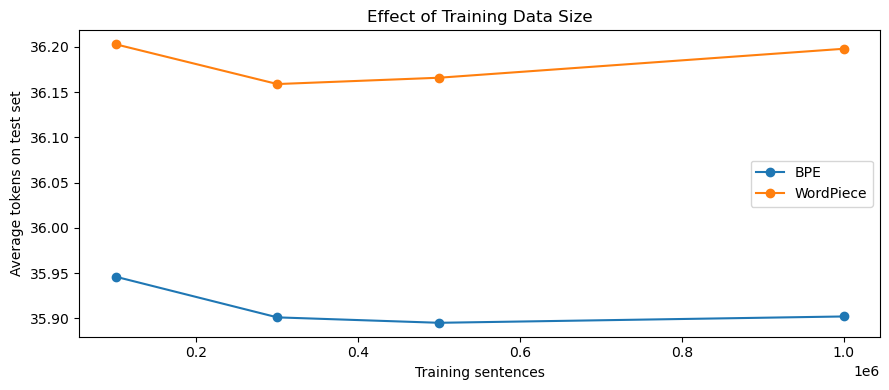

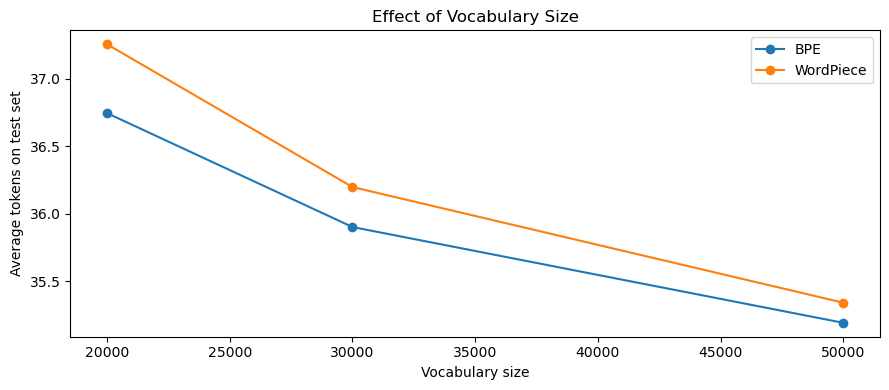

In [8]:
plot_df = results_df[results_df["split"] == "test"].copy()

plt.figure(figsize=(9, 4))
for algo in plot_df["algorithm"].unique():
    part = plot_df[(plot_df["experiment"] == "training_size") & (plot_df["algorithm"] == algo)]
    plt.plot(part["train_size"], part["avg_tokens"], marker="o", label=algo)
plt.xlabel("Training sentences")
plt.ylabel("Average tokens on test set")
plt.title("Effect of Training Data Size")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
for algo in plot_df["algorithm"].unique():
    part = plot_df[(plot_df["experiment"] == "vocab_size") & (plot_df["algorithm"] == algo)]
    plt.plot(part["vocab_size"], part["avg_tokens"], marker="o", label=algo)
plt.xlabel("Vocabulary size")
plt.ylabel("Average tokens on test set")
plt.title("Effect of Vocabulary Size")
plt.legend()
plt.tight_layout()
plt.show()

## Step 9 - Save Tokenizers

The trained tokenizers are saved as JSON files so you can reuse them later.

In [9]:
TOKENIZER_DIR = DATA_DIR / "tokenizers"
TOKENIZER_DIR.mkdir(exist_ok=True)

for (algo, train_size, vocab_size), tokenizer in trained_tokenizers.items():
    path = TOKENIZER_DIR / f"{LANGUAGE_CODE}_{algo.lower()}_train{train_size}_vocab{vocab_size}.json"
    tokenizer.save(str(path))

print(f"Saved {len(trained_tokenizers)} tokenizers in {TOKENIZER_DIR}")
print("Results:", RESULTS_CSV)

Saved 12 tokenizers in lab03_data\tokenizers
Results: lab03_data\hin_Deva_tokenization_results.csv


## Conclusion Template

Use `results_df` and `examples_df` to write your final observations. Usually, larger training data and larger vocabulary reduce token counts because the tokenizer learns more complete subwords.

In [10]:
best_rows = results_df[results_df["split"] == "test"].sort_values("avg_tokens").head(5)
best_rows

,split,avg_tokens,median_tokens,max_tokens,unk_rate,experiment,algorithm,train_size,vocab_size
25,test,35.193,25.0,124,0.0,vocab_size,BPE,1000000,50000
27,test,35.342,25.0,128,0.0,vocab_size,WordPiece,1000000,50000
9,test,35.895,26.0,131,0.0,training_size,BPE,500000,30000
5,test,35.901,26.0,134,0.0,training_size,BPE,300000,30000
13,test,35.902,26.0,131,0.0,training_size,BPE,1000000,30000
